# Permutation alignment before averaging

Recover the hidden-unit correspondence between two equivalent networks.

Permuting hidden units and applying the same permutation to outgoing weights preserves the function. Fit an assignment using incoming weights and biases, reorder the second model, then compare interpolation errors before and after alignment. This is the one-hidden-layer case of weight matching.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

raw midpoint MSE 1.22093, aligned 0.00e+00


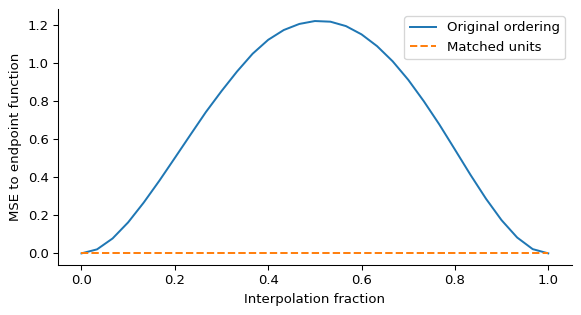

In [2]:
rng = np.random.default_rng(31)
W = rng.normal(size=(9, 2))
b = rng.normal(size=9)
v = rng.normal(size=9)
perm = rng.permutation(9)
U, d, z = W[perm], b[perm], v[perm]
X = rng.normal(size=(300, 2))


def f(x, w, b, v):
    return np.maximum(0, x @ w.T + b) @ v


truth = f(X, W, b, v)
rows, order = linear_sum_assignment(cdist(np.c_[W, b], np.c_[U, d], metric="sqeuclidean"))
assert np.array_equal(rows, np.arange(len(W)))
ts = np.linspace(0, 1, 31)


def path(q):
    return np.array(
        [
            np.mean(
                (
                    f(X, (1 - t) * W + t * U[q], (1 - t) * b + t * d[q], (1 - t) * v + t * z[q])
                    - truth
                )
                ** 2
            )
            for t in ts
        ]
    )


raw = path(np.arange(len(W)))
aligned = path(order)
print(f"raw midpoint MSE {raw[15]:.5f}, aligned {aligned[15]:.2e}")
assert aligned.max() < 1e-20
fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
ax.plot(ts, raw, label="Original ordering")
ax.plot(ts, aligned, "--", label="Matched units")
ax.set(xlabel="Interpolation fraction", ylabel="MSE to endpoint function")
ax.legend()
plt.show()

## Interpreting the result

Two endpoints can agree on every input and still interpolate poorly. The assignment succeeds here because one model is an exact permutation of the other.

## Exercise

Perturb the second model before matching and measure the remaining interpolation error.

## References

[Ainsworth et al., Git Re-Basin (2022)](https://arxiv.org/abs/2209.04836)